# 01 — Análise exploratória (EDA)

**Objetivo:** entender quais colunas existem, que valores elas assumem e como se ligam.

- Fonte: Kaggle `omenkj/social-media-sponsorship-and-engagement-dataset` → um único arquivo, `social_media_dataset.csv`.
- "Ligação entre datasets": o arquivo é uma tabela única (*flat*), que mistura 4 entidades: **post**, **creator**, **patrocinador** e **audiência**. A seção 7 testa se essas entidades são consistentes.
- Para rodar: `.venv/bin/jupyter lab` dentro de `submissions/rafael/`.

In [1]:
# Setup: load data and set a single, quiet chart style.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "raw" / "social_media_dataset.csv"

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": GRAY, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE]),
})
pd.set_option("display.max_colwidth", 60)

df = pd.read_csv(DATA)
df["post_date"] = pd.to_datetime(df["post_date"], format="%m/%d/%y %I:%M %p")
print(f"{len(df):,} linhas × {df.shape[1]} colunas")
df.head(3).T

52,214 linhas × 27 colunas


,0,1,2
id,1,2,3
platform,RedNote,Bilibili,Bilibili
content_id,content_20586,content_14129,content_28653
creator_id,creator_586,creator_4129,creator_3653
creator_name,nicole85,irogers,jessicaanderson
content_url,http://www.hill-montgomery.com/,https://anderson.com/,https://www.ramos.com/
content_type,video,image,image
content_category,beauty,lifestyle,beauty
post_date,2023-05-29 00:15:00,2023-05-29 00:18:00,2023-05-29 00:27:00
language,Hindi,Hindi,English


## 1. Dicionário de dados
Tipo, cardinalidade, nulos e exemplos de cada coluna.

In [2]:
def data_dictionary(frame: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "tipo": frame.dtypes.astype(str),
        "valores_unicos": frame.nunique(),
        "%_unicos": (frame.nunique() / len(frame) * 100).round(1),
        "%_nulos": (frame.isna().mean() * 100).round(1),
        "exemplos": [frame[c].dropna().astype(str).unique()[:4].tolist() for c in frame],
    })

data_dictionary(df)

,tipo,valores_unicos,%_unicos,%_nulos,exemplos
id,int64,52214,100.0,0.0,"[1, 2, 3, 4]"
platform,str,5,0.0,0.0,"[RedNote, Bilibili, YouTube, TikTok]"
content_id,str,52214,100.0,0.0,"[content_20586, content_14129, content_28653, content_10..."
creator_id,str,5000,9.6,0.0,"[creator_586, creator_4129, creator_3653, creator_397]"
creator_name,str,42213,80.8,0.0,"[nicole85, irogers, jessicaanderson, matthewyork]"
content_url,str,28037,53.7,0.0,"[http://www.hill-montgomery.com/, https://anderson.com/,..."
content_type,str,4,0.0,0.0,"[video, image, mixed, text]"
content_category,str,3,0.0,0.0,"[beauty, lifestyle, tech]"
post_date,datetime64[us],50905,97.5,0.0,"[2023-05-29 00:15:00, 2023-05-29 00:18:00, 2023-05-29 00..."
language,str,5,0.0,0.0,"[Hindi, English, Chinese, Japanese]"


### Grupos de colunas

| Grupo | Colunas | Observação |
|---|---|---|
| Identificadores | `id`, `content_id`, `content_url` | `id`/`content_id` são únicos por linha |
| Creator | `creator_id`, `creator_name`, `follower_count` | ver seção 7 (consistência) |
| Conteúdo | `platform`, `content_type`, `content_category`, `language`, `content_length`, `content_description`, `hashtags` | |
| Tempo | `post_date` | |
| Métricas | `views`, `likes`, `shares`, `comments_count`, `comments_text` | não existe `engagement_rate` → calculada abaixo |
| Patrocínio | `is_sponsored`, `disclosure_type`, `disclosure_location`, `sponsor_name`, `sponsor_category` | |
| Audiência | `audience_age_distribution`, `audience_gender_distribution`, `audience_location` | valor único (grupo predominante), não uma distribuição |

In [3]:
# Derived columns used throughout the notebook.
df["interactions"] = df[["likes", "shares", "comments_count"]].sum(axis=1)
df["eng_rate_views"] = df["interactions"] / df["views"]
df["eng_rate_followers"] = df["interactions"] / df["follower_count"]
df["n_hashtags"] = df["hashtags"].fillna("").str.split(",").map(lambda tags: sum(bool(t) for t in tags))
df["month"] = df["post_date"].dt.to_period("M").dt.to_timestamp()

## 2. Colunas categóricas — distribuição dos valores

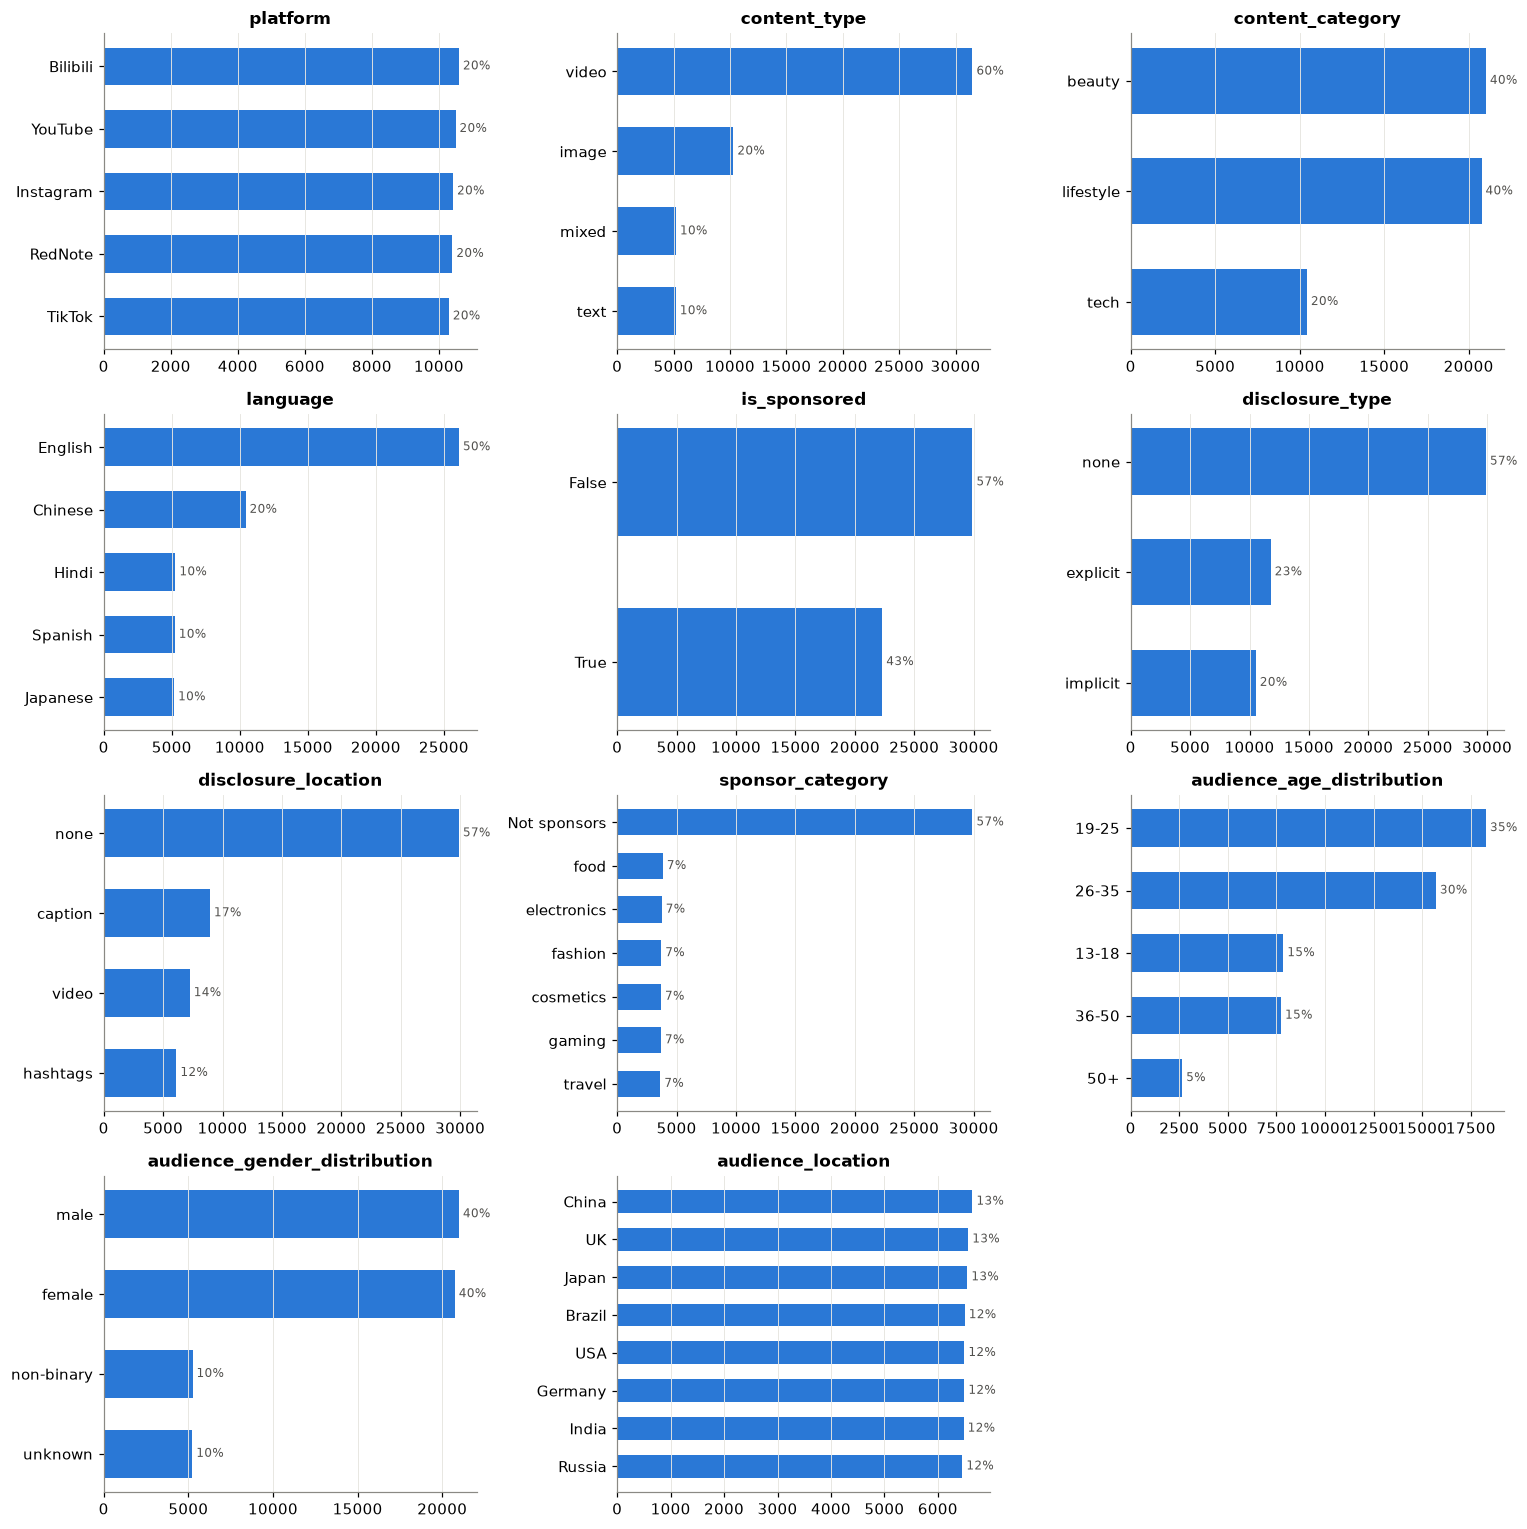

In [4]:
CATEGORICAL = ["platform", "content_type", "content_category", "language", "is_sponsored",
               "disclosure_type", "disclosure_location", "sponsor_category",
               "audience_age_distribution", "audience_gender_distribution", "audience_location"]

def bar_counts(ax, series: pd.Series, title: str) -> None:
    counts = series.value_counts().sort_values()
    ax.barh(counts.index.astype(str), counts.values, color=BLUE, height=0.6)
    for y, v in enumerate(counts.values):
        ax.text(v, y, f" {v / counts.sum():.0%}", va="center", fontsize=8, color="#52514e")
    ax.set_title(title); ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(4, 3, figsize=(14, 14))
for ax, col in zip(axes.flat, CATEGORICAL):
    bar_counts(ax, df[col], col)
axes.flat[-1].axis("off")
fig.tight_layout()

## 3. Colunas numéricas — distribuição

,count,mean,std,min,25%,50%,75%,max
views,52214.0,10100.3,100.0,9676.0,10032.0,10100.0,10168.0,10551.0
likes,52214.0,1510.3,38.9,1354.0,1484.0,1510.0,1536.0,1668.0
shares,52214.0,300.0,17.3,227.0,288.0,300.0,312.0,380.0
comments_count,52214.0,200.0,14.1,140.0,190.0,200.0,210.0,258.0
follower_count,52214.0,499884.5,288044.6,1013.0,250817.8,498490.0,749818.8,999998.0
content_length,52214.0,229.5,167.1,10.0,95.0,174.0,360.0,599.0


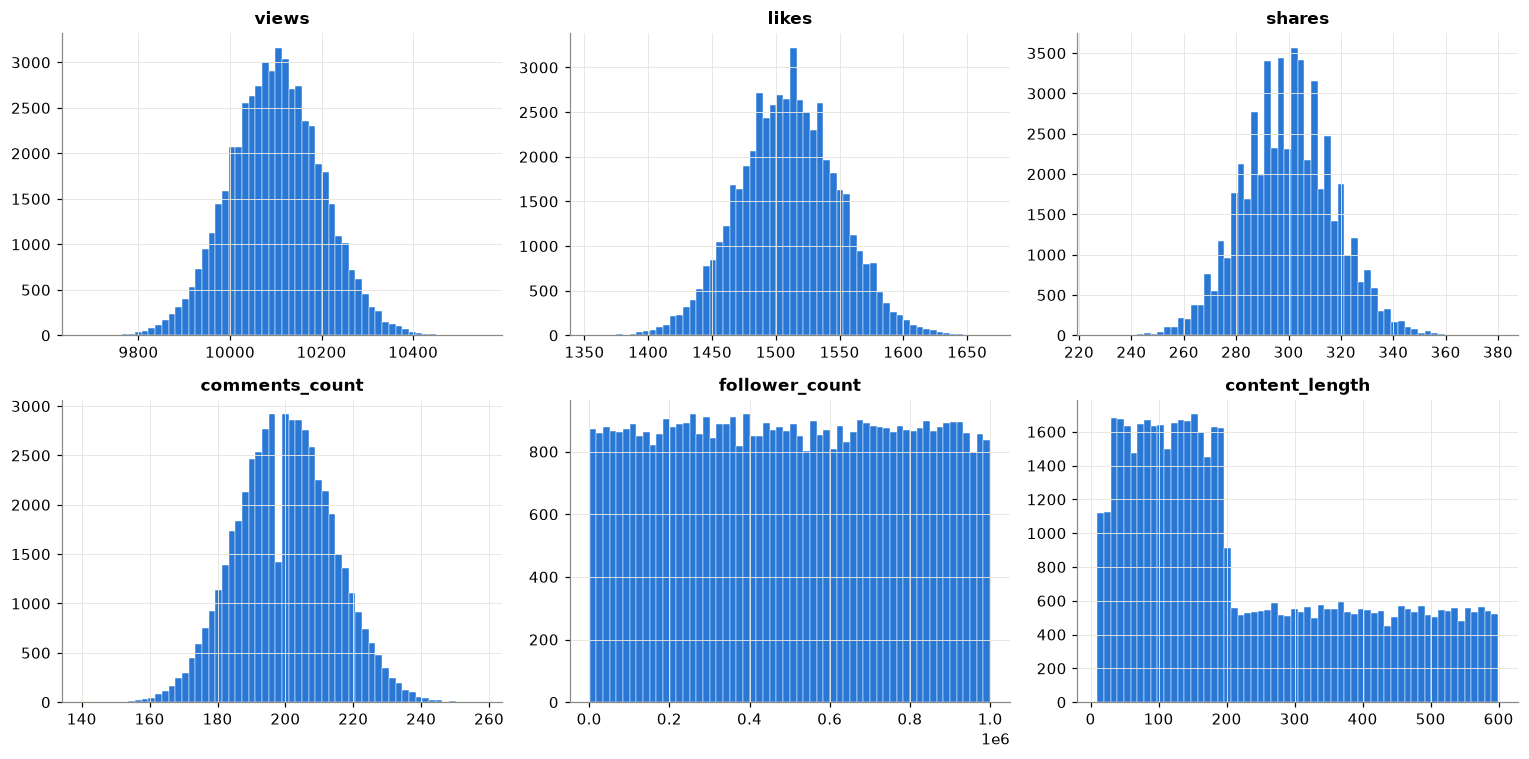

In [5]:
NUMERIC = ["views", "likes", "shares", "comments_count", "follower_count", "content_length"]
display(df[NUMERIC].describe().T.round(1))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, NUMERIC):
    ax.hist(df[col], bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
    ax.set_title(col)
fig.tight_layout()

**Leitura:** `views`, `likes`, `shares` e `comments_count` formam sinos estreitos (ex.: views 10.100 ± 100), sem cauda longa e sem posts virais.
Isso é a assinatura de uma **distribuição de Poisson** (variância ≈ média). `follower_count` é plana de 0 a 1M (uniforme).

In [6]:
for col in ["views", "likes", "shares", "comments_count"]:
    print(f"{col:15s} média={df[col].mean():8.1f}  variância/média={df[col].var() / df[col].mean():.2f}")
print("follower_count vs. Uniforme(0, 1M): KS p =", round(stats.kstest(df.follower_count / 1e6, "uniform").pvalue, 3))

views           média= 10100.3  variância/média=0.99
likes           média=  1510.3  variância/média=1.00
shares          média=   300.0  variância/média=1.00
comments_count  média=   200.0  variância/média=0.99
follower_count vs. Uniforme(0, 1M): KS p = 0.865


## 4. Tempo

Período: 2023-05-29 → 2025-05-28


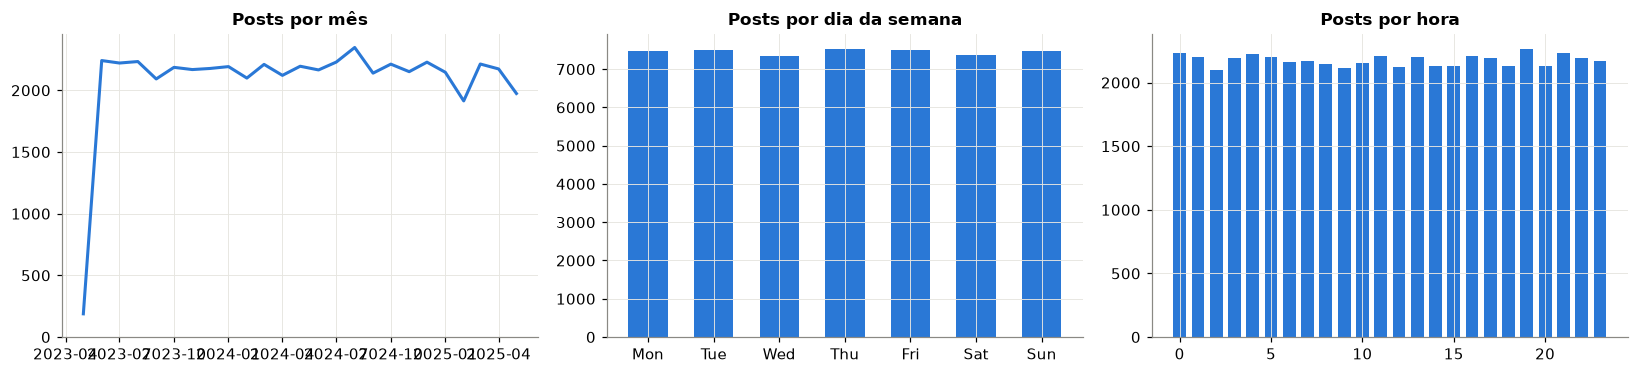

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
monthly = df.groupby("month").size()
axes[0].plot(monthly.index, monthly.values, color=BLUE, linewidth=2); axes[0].set_title("Posts por mês")
axes[0].set_ylim(0)
dow = df["post_date"].dt.day_name().value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
axes[1].bar(dow.index.str[:3], dow.values, color=BLUE, width=0.6); axes[1].set_title("Posts por dia da semana")
hour = df["post_date"].dt.hour.value_counts().sort_index()
axes[2].bar(hour.index, hour.values, color=BLUE, width=0.7); axes[2].set_title("Posts por hora")
fig.tight_layout()
print("Período:", df.post_date.min().date(), "→", df.post_date.max().date())

## 5. Texto e hashtags

972 hashtags distintas


,content_description,hashtags,comments_text
26639,Manage perform necessary court throughout war personal r...,"across,perform",Quality film account difference system will sort charge.
44806,Event until and market himself cell religious this Repub...,NaN,Less threat open. Art institution whom result impact each.
11268,Happen market out season result since shoulder white can...,"customer,child",Behind well social operation rise term lot class. New so...
50884,Have until bill old great old since receive claim.,"most,push,pick,education",Face market before year involve. His according send addr...
5424,Form measure according hard can movement body price.,"late,entire",Work population relate watch. Mrs throw investment effort.


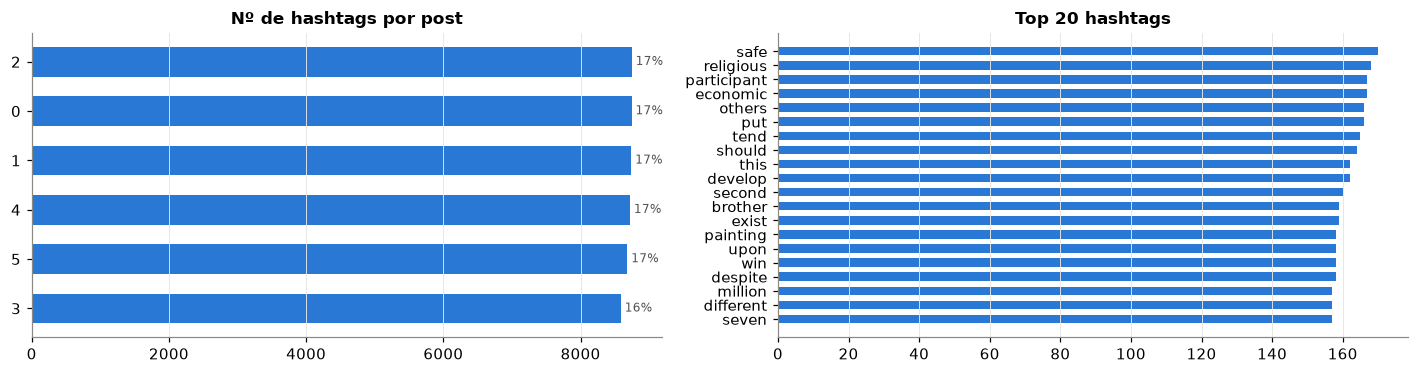

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
bar_counts(axes[0], df["n_hashtags"], "Nº de hashtags por post")
tags = df["hashtags"].dropna().str.split(",").explode().str.strip()
top = tags.value_counts().head(20).sort_values()
axes[1].barh(top.index, top.values, color=BLUE, height=0.6); axes[1].set_title("Top 20 hashtags")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
print(f"{tags.nunique():,} hashtags distintas")
df[["content_description", "hashtags", "comments_text"]].sample(5, random_state=0)

**Leitura:** as hashtags, legendas e comentários são palavras genéricas em inglês (geradas pela biblioteca *Faker*), sem relação com a categoria ou o idioma do post.

## 6. Coluna de patrocínio — como os campos se relacionam

In [9]:
display(pd.crosstab(df["is_sponsored"], df["disclosure_type"], margins=True))
display(pd.crosstab(df["disclosure_type"], df["disclosure_location"]))
display(pd.crosstab(df["is_sponsored"], df["sponsor_category"]))
sponsors = df.loc[df.is_sponsored, "sponsor_name"]
print(f"{sponsors.nunique():,} patrocinadores distintos em {len(sponsors):,} posts patrocinados")
print("Posts por patrocinador:", sponsors.value_counts().describe().round(2).to_dict())

disclosure_type,explicit,implicit,none,All
is_sponsored,,,,
False,0,0,29900,29900
True,11784,10530,0,22314
All,11784,10530,29900,52214


disclosure_location,caption,hashtags,none,video
disclosure_type,,,,
explicit,4765,3180,0,3839
implicit,4179,2944,0,3407
none,0,0,29900,0


sponsor_category,Not sponsors,cosmetics,electronics,fashion,food,gaming,travel
is_sponsored,,,,,,,
False,29900,0,0,0,0,0,0
True,0,3688,3750,3710,3846,3687,3633


18,005 patrocinadores distintos em 22,314 posts patrocinados
Posts por patrocinador: {'count': 18005.0, 'mean': 1.24, 'std': 1.17, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 32.0}


## 7. Ligação entre entidades (chaves e consistência)

```
creator (creator_id) ──1:N── post (id / content_id) ──N:1── sponsor (sponsor_name → sponsor_category)
                                  │
                                  └── audiência (age, gender, location) — atributos do post
```
Testes: cada chave identifica de fato uma entidade estável?

In [10]:
def per_key(key: str, attr: str) -> pd.Series:
    return df.groupby(key)[attr].nunique()

checks = {
    "content_id único por linha": df["content_id"].is_unique,
    "content_url único por linha": df["content_url"].is_unique,
    "nomes por creator_id (mediana)": per_key("creator_id", "creator_name").median(),
    "follower_count distintos por creator (mediana)": per_key("creator_id", "follower_count").median(),
    "plataformas por creator (mediana)": per_key("creator_id", "platform").median(),
    "categorias por creator (mediana)": per_key("creator_id", "content_category").median(),
    "categorias por sponsor_name (máx.)": df[df.is_sponsored].groupby("sponsor_name")["sponsor_category"].nunique().max(),
    "posts por creator (mediana)": df["creator_id"].value_counts().median(),
}
pd.Series(checks, name="resultado").to_frame()

,resultado
content_id único por linha,True
content_url único por linha,False
nomes por creator_id (mediana),10.0
follower_count distintos por creator (mediana),10.0
plataformas por creator (mediana),5.0
categorias por creator (mediana),3.0
categorias por sponsor_name (máx.),6
posts por creator (mediana),10.0


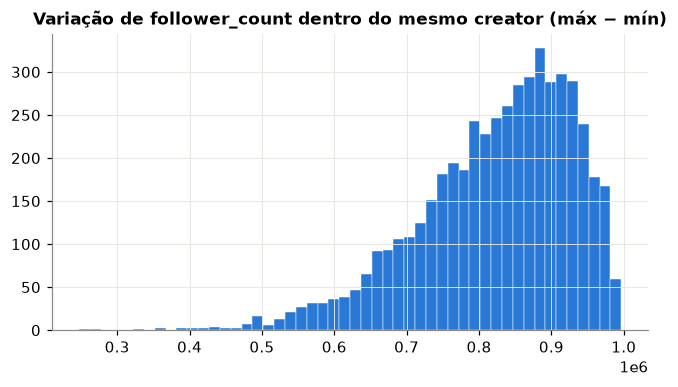

In [11]:
# How unstable is follower_count within the same creator?
spread = df.groupby("creator_id")["follower_count"].agg(["min", "max"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(spread["max"] - spread["min"], bins=50, color=BLUE, edgecolor="white", linewidth=0.3)
ax.set_title("Variação de follower_count dentro do mesmo creator (máx − mín)")
plt.show()

**Leitura:** `creator_id` **não** é uma entidade estável: o mesmo id tem ~10 nomes, ~10 contagens de seguidores (que variam em centenas de milhares) e posta em todas as plataformas e categorias.
Análises "por creator" ou "por faixa de seguidores" exigem cuidado: `follower_count` só vale no nível do post.

## 8. Relação entre colunas

### 8.1 Numéricas — correlação (Spearman)

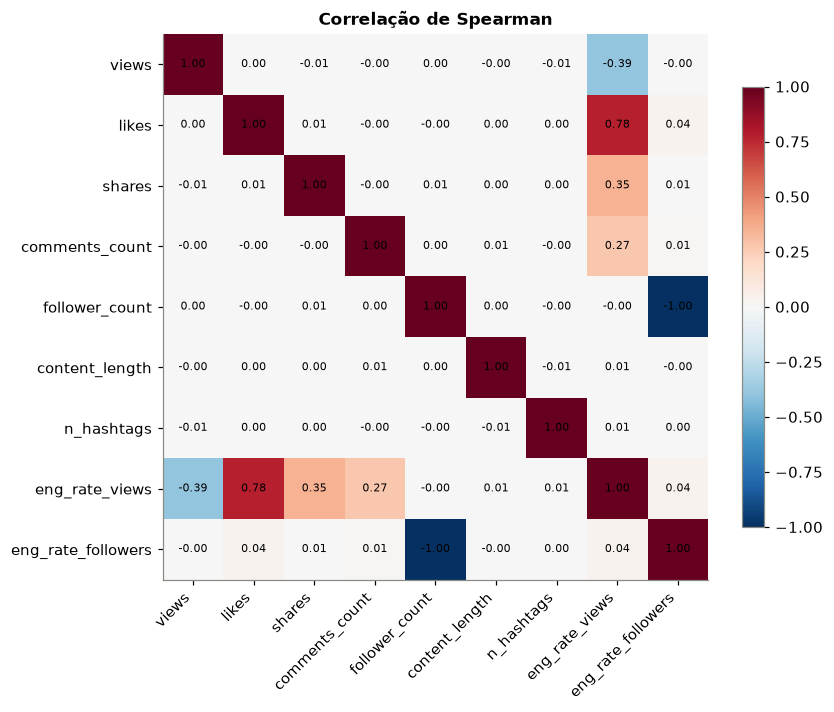

In [12]:
NUM_ALL = NUMERIC + ["n_hashtags", "eng_rate_views", "eng_rate_followers"]
corr = df[NUM_ALL].corr("spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im, shrink=0.8); ax.set_title("Correlação de Spearman")
plt.show()

**Leitura:** fora as relações mecânicas (a taxa de engajamento é calculada a partir de likes/views/followers), tudo é ≈ 0. Views não sobem com seguidores, likes não sobem com views.

### 8.2 Categóricas — associação entre si (V de Cramér)

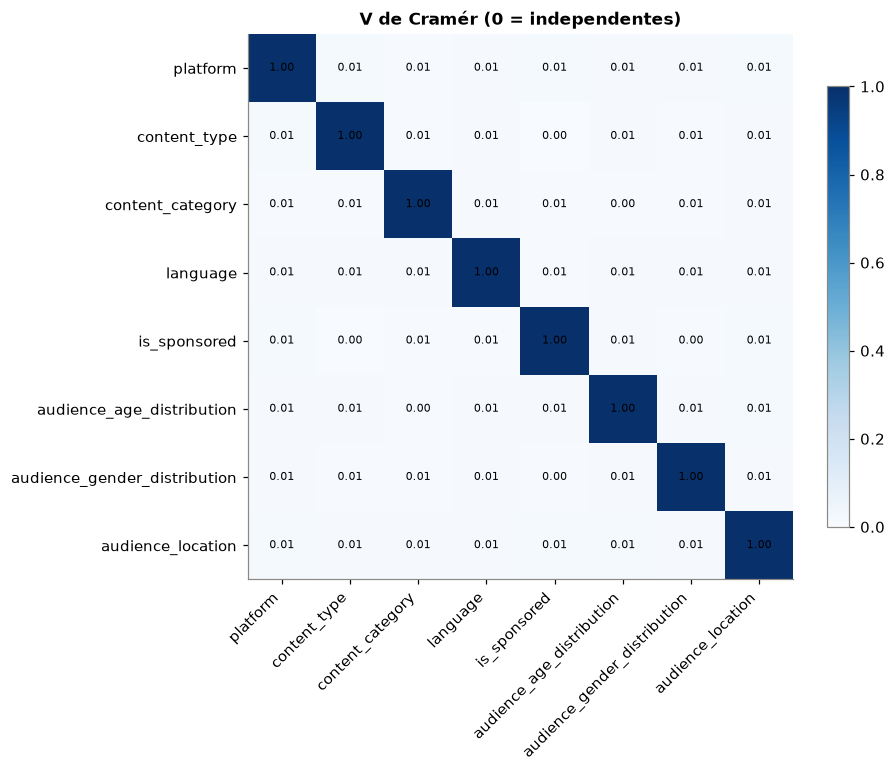

In [13]:
def cramers_v(a: pd.Series, b: pd.Series) -> float:
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

CAT_ASSOC = [c for c in CATEGORICAL if c not in ("disclosure_type", "disclosure_location", "sponsor_category")]
cv = pd.DataFrame([[cramers_v(df[a], df[b]) for b in CAT_ASSOC] for a in CAT_ASSOC], CAT_ASSOC, CAT_ASSOC)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cv, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cv)), cv.columns, rotation=45, ha="right"); ax.set_yticks(range(len(cv)), cv.index)
for i in range(len(cv)):
    for j in range(len(cv)):
        ax.text(j, i, f"{cv.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im, shrink=0.8); ax.set_title("V de Cramér (0 = independentes)")
plt.show()

**Leitura:** as categorias foram sorteadas de forma independente umas das outras (ex.: idioma não depende do país da audiência).

### 8.3 Engajamento por grupo (média ± IC 95%)

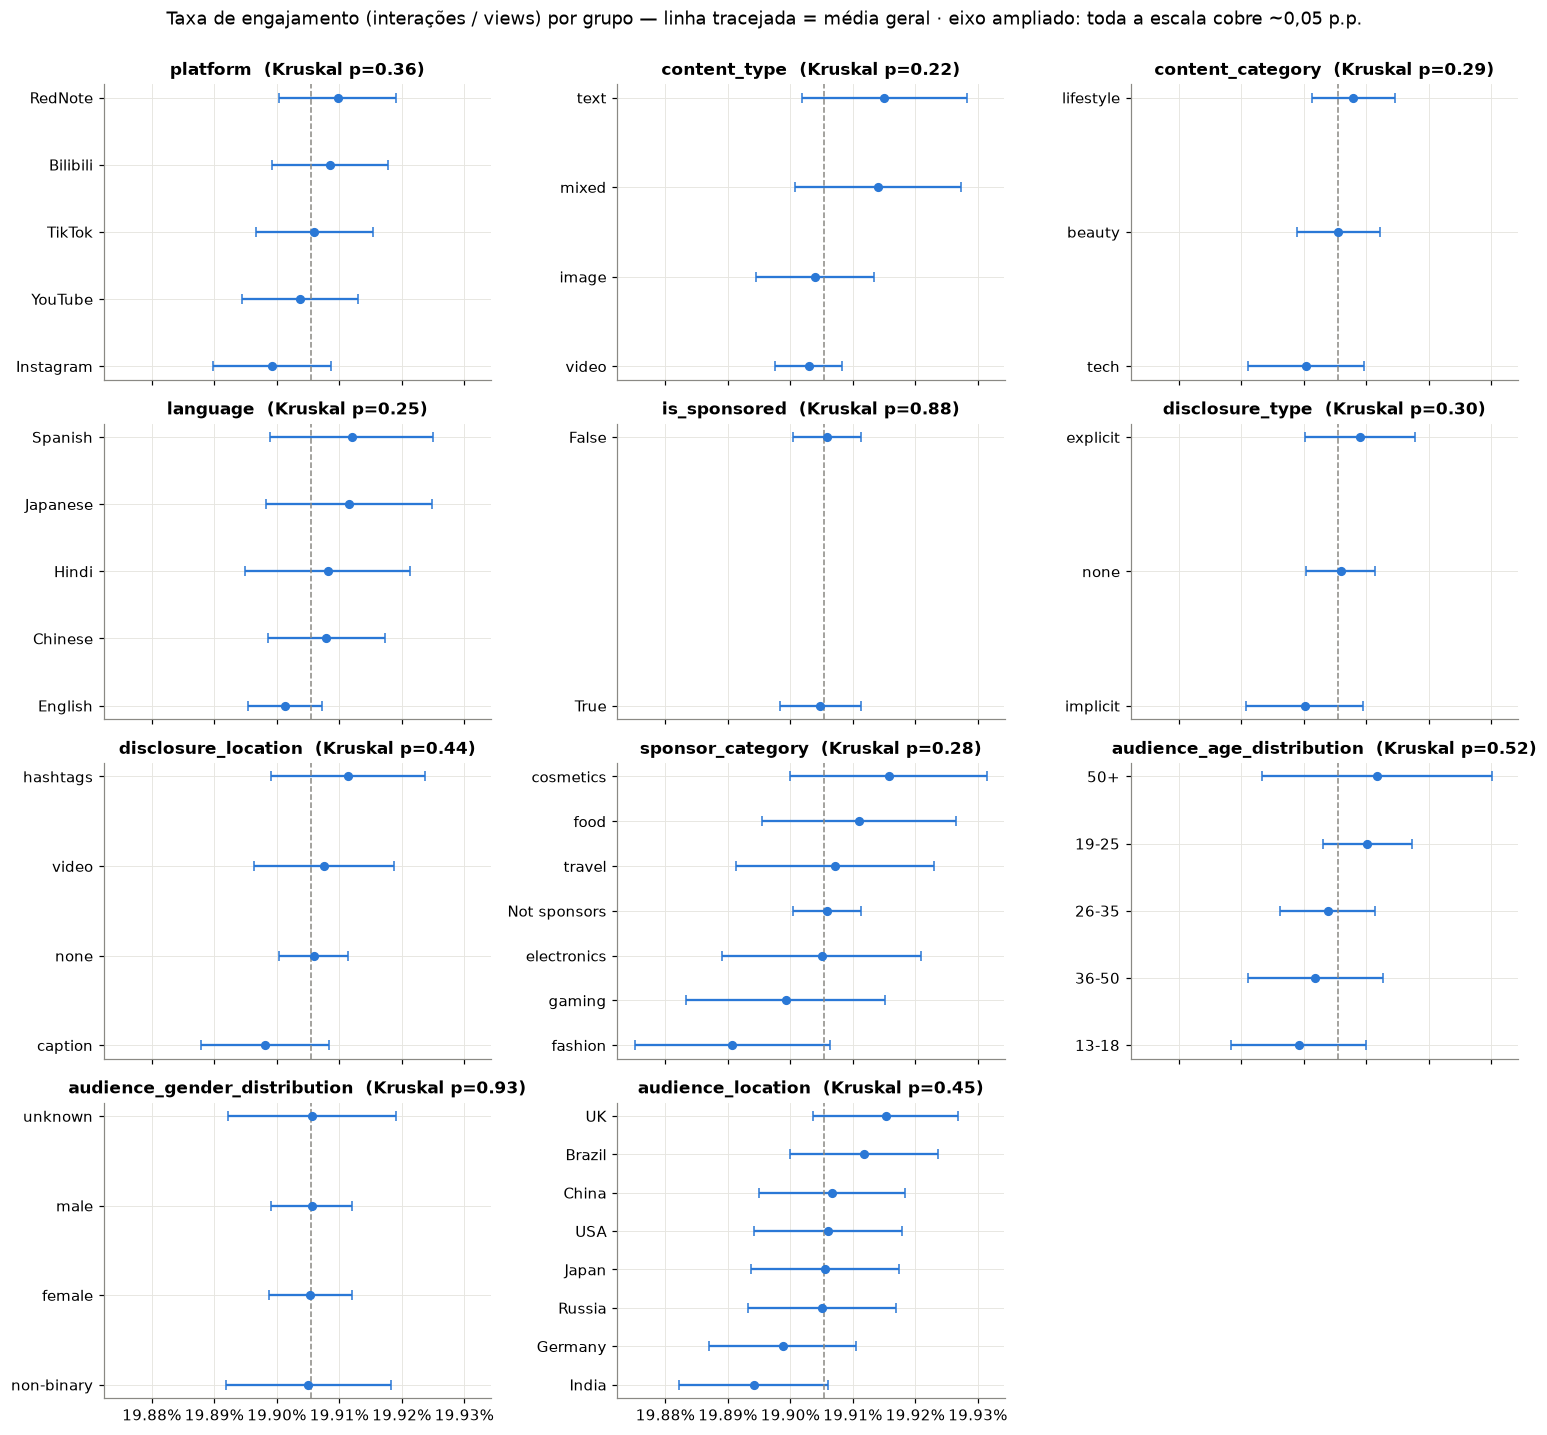

In [14]:
def mean_ci(frame: pd.DataFrame, col: str, metric: str = "eng_rate_views") -> pd.DataFrame:
    g = frame.groupby(col)[metric].agg(["mean", "sem", "count"])
    g["ci95"] = 1.96 * g["sem"]
    return g.sort_values("mean")

fig, axes = plt.subplots(4, 3, figsize=(14, 13), sharex=True)
for ax, col in zip(axes.flat, CATEGORICAL):
    g = mean_ci(df, col)
    p = stats.kruskal(*[x.values for _, x in df.groupby(col)["eng_rate_views"]]).pvalue
    ax.errorbar(g["mean"], g.index.astype(str), xerr=g["ci95"], fmt="o", color=BLUE, markersize=5, capsize=3)
    ax.axvline(df["eng_rate_views"].mean(), color=GRAY, linewidth=1, linestyle="--")
    ax.set_title(f"{col}  (Kruskal p={p:.2f})")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=2))
axes.flat[-1].axis("off")
fig.suptitle("Taxa de engajamento (interações / views) por grupo — linha tracejada = média geral · eixo ampliado: toda a escala cobre ~0,05 p.p.", y=1.0)
fig.tight_layout()

**Leitura:** todos os intervalos se sobrepõem à média geral (~19,9%) e nenhum teste é significativo (p > 0,05).

### 8.4 Engajamento × seguidores e × duração

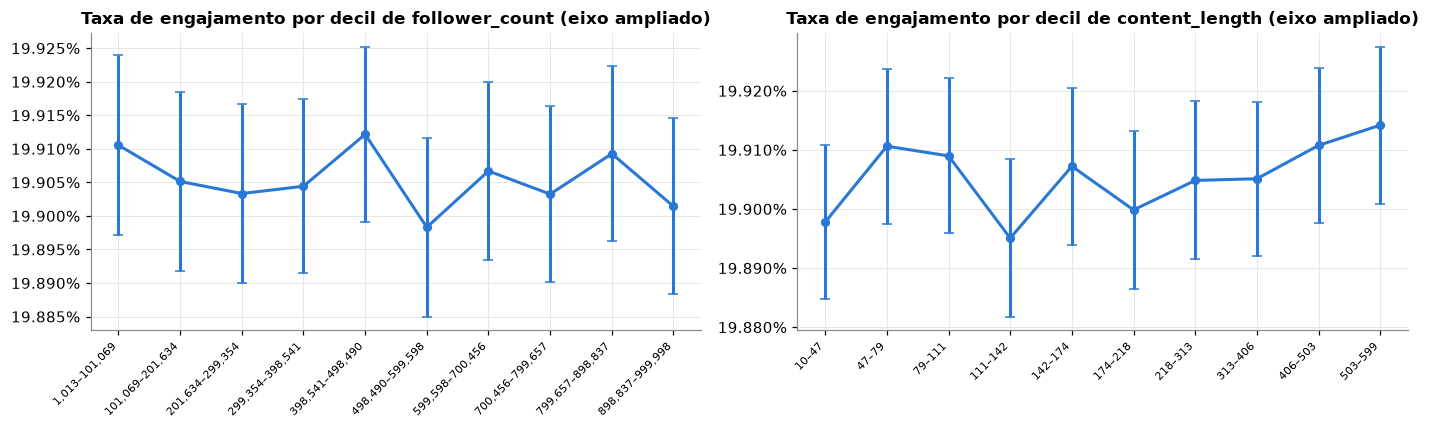

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, bins in [(axes[0], "follower_count", 10), (axes[1], "content_length", 10)]:
    binned = pd.qcut(df[col], bins)
    g = df.groupby(binned, observed=True)["eng_rate_views"].agg(["mean", "sem"])
    labels = [f"{iv.left:,.0f}–{iv.right:,.0f}" for iv in g.index]
    ax.errorbar(range(len(g)), g["mean"], yerr=1.96 * g["sem"], fmt="o-", color=BLUE, markersize=5, linewidth=2, capsize=3)
    ax.set_xticks(range(len(g)), labels, rotation=45, ha="right", fontsize=7)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=3))
    ax.set_title(f"Taxa de engajamento por decil de {col} (eixo ampliado)")
fig.tight_layout()

In [16]:
# Same check for sponsorship, split by platform and content type (the "fair comparison" from the brief).
pivot = df.pivot_table("eng_rate_views", ["platform", "content_type"], "is_sponsored").rename(columns={False: "orgânico", True: "patrocinado"})
pivot["diferença_pp"] = ((pivot["patrocinado"] - pivot["orgânico"]) * 100).round(3)
pivot.round(4)

is_sponsored            orgânico  patrocinado  diferença_pp
platform  content_type                                     
Bilibili  image           0.1990       0.1991         0.015
          mixed           0.1992       0.1992         0.003
          text            0.1993       0.1990        -0.032
          video           0.1991       0.1990        -0.007
Instagram image           0.1989       0.1992         0.033
          mixed           0.1990       0.1993         0.024
          text            0.1988       0.1992         0.034
          video           0.1990       0.1989        -0.002
RedNote   image           0.1993       0.1992        -0.007
          mixed           0.1992       0.1992         0.008
          text            0.1991       0.1995         0.045
          video           0.1990       0.1991         0.010
TikTok    image           0.1989       0.1990         0.011
          mixed           0.1994       0.1989        -0.049
          text            0.1992       0.1989        -0.032
          video           0.1992       0.1990        -0.015
YouTube   image           0.1990       0.1989        -0.008
          mixed           0.1989       0.1993         0.039
          text            0.1993       0.1992        -0.018
          video           0.1991       0.1989        -0.013

## 9. Resumo da EDA

1. **Estrutura:** 52.214 posts × 27 colunas, um único arquivo; nulos só em `hashtags` (16,7%) e `comments_text` (16,6%).
2. **Categorias:** distribuições quase uniformes (ex.: 5 plataformas com ~20% cada); vídeo = 60% dos posts; 43% dos posts são patrocinados.
3. **Métricas:** Poisson com médias fixas → sem viralização, sem posts com engajamento zero.
4. **Entidades:** `content_id` é uma chave confiável; `creator_id` não (nomes e seguidores mudam a cada post).
5. **Relações:** nenhuma variável explica o engajamento (todos p > 0,05; correlações ≈ 0).